# 3.1 Household groups: seasonal patterns and clusters

**Question.** How strongly does each group of households' electricity and gas use rise in winter, did every group cut back after 2020, and which groups share the same seasonal shape?

**Data.** SERL cleaned daily-statistics file (monthly rows, 2020–2023). It is built from the raw SERL file by `python scripts/make_dataset.py` (`serl_energy.dataset.make_clean_daily`: column names and row order only, no values changed; a test checks the rebuild matches the file). Each group's series is one quantity, kWh/day per household, all days.

**Groups.** All households, PV / no PV, gas / electric heating, and every level of every SERL characteristic except temperature band (which describes the weather on a day, not a type of household): 75 groups. Group names come from `serl_energy.labels`.

**Method.** Per group: mean 2023 use, winter/summer ratio (Dec–Feb vs Jun–Aug), STL seasonal strength (0 = none, 1 = purely seasonal) and the change 2020→2023. Then k-means on each group's seasonal *shape* (monthly profile divided by its own mean), k chosen by silhouette.

**Outputs.** Figures in `reports/figures/3.1-household-seasonality/`, tables in `reports/tables/3.1-household-seasonality/`.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

from serl_energy import dataset as serl, plots
from serl_energy.labels import household_groups, role
from serl_energy.plots import COLORS, INK, ROLE_COLORS
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=UserWarning)
plots.use_theme()
reporter = Reporter("3.1-household-seasonality")

monthly_all = serl.load_monthly(serl.CLEAN_CSV)
# keep only the rows used here (per-household kWh/day, all days) so slicing is fast
monthly = monthly_all[monthly_all["unit"].eq("kWh/day") & monthly_all["weekday_weekend"].eq("both")]
GROUPS = household_groups(monthly)
print(f"{len(GROUPS)} household groups")

QUANTITIES = {"Electricity imports": COLORS["electricity"], "Gas": COLORS["gas"]}
WINTER, SUMMER = [12, 1, 2], [6, 7, 8]
MONTHS = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()


def seasonal_strength(y):
    res = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))

75 household groups


## 1. Seasonal measures per group

SERL suppresses months with too few households, so groups with any missing month are skipped (listed below).


In [2]:
series, rows, skipped = {q: {} for q in QUANTITIES}, [], []
for q in QUANTITIES:
    for label, f in GROUPS:
        s = serl.monthly_series(monthly, q, "kWh/day", **f)
        if s.isna().any():
            skipped.append(f"{q} | {label} ({s.isna().sum()} months missing)")
            continue
        series[q][label] = s
        rows.append({"quantity": q, "group_label": label, "segment": f.get("segment", ""),
                     "segment_value": f.get("segment_value", ""),
                     "role": role(f["segment"], f["segment_value"]) if "segment" in f else "other",
                     "kwh_per_day_2023": s.loc["2023"].mean(),
                     "winter_to_summer": s[s.index.month.isin(WINTER)].mean() / s[s.index.month.isin(SUMMER)].mean(),
                     "seasonal_strength": seasonal_strength(s),
                     "change_2020_2023_pct": 100 * (s.loc["2023"].mean() / s.loc["2020"].mean() - 1)})
seasonality = pd.DataFrame(rows)
print(f"Skipped (incomplete series): {len(skipped)}")
for line in skipped:
    print("  ", line)
for q in QUANTITIES:
    t = seasonality[seasonality["quantity"].eq(q)].set_index("group_label")
    cols = ["kwh_per_day_2023", "winter_to_summer", "seasonal_strength", "change_2020_2023_pct"]
    print(f"\n{q}: {len(t)} groups. Most and least seasonal")
    print(pd.concat([t.nlargest(6, "winter_to_summer"), t.nsmallest(6, "winter_to_summer")])[cols].round(2).to_string())
    print(f"  groups that used less in 2023 than 2020: {(t['change_2020_2023_pct'] < 0).sum()} of {len(t)}")
reporter.save_table(seasonality, "group_seasonality")

Skipped (incomplete series): 6
   Gas | District or community (48 months missing)
   Gas | Electric radiators (1 months missing)
   Gas | Electric storage radiators (6 months missing)
   Gas | Oil, solid fuel or biomass (48 months missing)
   Gas | Other electric (48 months missing)
   Gas | Other or other mix (1 months missing)

Electricity imports: 75 groups. Most and least seasonal
                            kwh_per_day_2023  winter_to_summer  seasonal_strength  change_2020_2023_pct
group_label                                                                                            
Electric storage radiators             13.61              3.49               0.95                -18.93
Other electric                         18.39              3.17               0.91                -25.91
Electric heating                       13.18              2.91               0.93                -21.32
Electric radiators                     11.62              2.76               0.94           

**Seasonality against the post-2020 cut-back.** Each point is a household group: how seasonal its use is (x) and how much it changed from 2020 to 2023 (y). Groups linked to energy poverty are red, comparators violet. **Look for:** every group sits below zero (all cut back); electric-heated groups are far to the right for electricity; deprived and comparator groups are mixed together rather than separated.


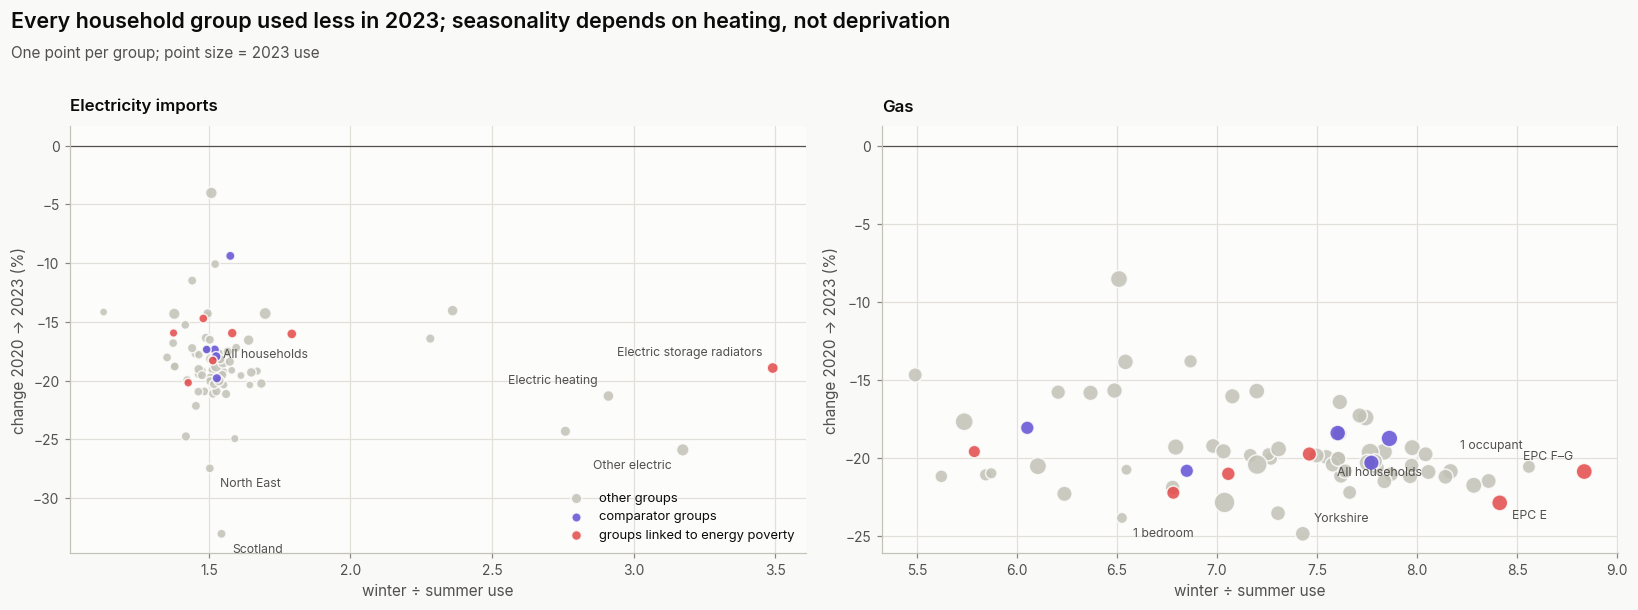

In [3]:
NUDGE = {("Gas", "1 occupant"): (-4, 12), ("Gas", "EPC E"): (8, -10)}   # hand placement where labels collide
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, q in zip(axes, QUANTITIES):
    t = seasonality[seasonality["quantity"].eq(q)]
    for r in ("other", "comparator", "vulnerable"):
        d = t[t["role"].eq(r)]
        ax.scatter(d["winter_to_summer"], d["change_2020_2023_pct"], s=12 + 3 * d["kwh_per_day_2023"],
                   color=ROLE_COLORS[r], alpha=0.85, edgecolor=COLORS["surface"], linewidth=1, zorder=3,
                   label={"other": "other groups", "comparator": "comparator groups",
                          "vulnerable": "groups linked to energy poverty"}[r])
    picks = pd.concat([t.nlargest(3, "winter_to_summer"), t.nsmallest(2, "change_2020_2023_pct"),
                       t[t["group_label"].eq("All households")]]).drop_duplicates("group_label")
    x_right = t["winter_to_summer"].quantile(0.97)
    for i, (_, row) in enumerate(picks.sort_values("winter_to_summer").iterrows()):
        right = row["winter_to_summer"] >= x_right          # labels near the right edge go to the left
        dx, dy = NUDGE.get((q, row["group_label"]), (-7 if right else 7, 8 if i % 2 else -12))
        ax.annotate(row["group_label"], (row["winter_to_summer"], row["change_2020_2023_pct"]),
                    xytext=(dx, dy), textcoords="offset points", fontsize=8,
                    color=INK["secondary"], ha="right" if dx < 0 else "left")
    ax.axhline(0, color=INK["secondary"], lw=0.8)
    ax.set_xlabel("winter ÷ summer use"); ax.set_ylabel("change 2020 → 2023 (%)")
    ax.set_title(q, loc="left", fontsize=11)
axes[0].legend(loc="lower right", fontsize=8.5)
plots.figure_title(fig, "Every household group used less in 2023; seasonality depends on heating, not deprivation",
                   "One point per group; point size = 2023 use")
reporter.save_fig(fig, "seasonality-vs-change")
plt.show()

## 2. Clustering the seasonal shapes

Each group's 2020–2023 series is averaged by calendar month and divided by its own mean, so groups are compared on the *shape* of their year, not their size. k-means runs for k = 2–6, and k is the largest within 0.01 of the best silhouette score. Clusters are named by their winter/summer ratio. In the chart, thick lines are cluster centres and thin lines the member groups; the more seasonal cluster is in the fuel's colour, the other in grey.


Electricity imports: silhouette by k {2: 0.835, 3: 0.433, 4: 0.444, 5: 0.416, 6: 0.407} -> k = 2
  largest monthly difference between cluster shapes: 0.39 x the group mean
  More seasonal (winter/summer ratio 2.78, 6 groups):
    PV; Electric heating; Electric radiators; Electric storage radiators; Other electric; Other or other mix
  Less seasonal (winter/summer ratio 1.51, 69 groups):
    All households; No PV; Gas heating; IMD 1 (most deprived); IMD 2; IMD 3; IMD 4; IMD 5 (least deprived); EPC A–B; EPC C; EPC D; EPC E; EPC F–G; Owner-occupied; Shared ownership; Private rent; Rent free; Social rent; Tenure: no answer; Commercial or no answer; Converted flat or shared house; Detached; Purpose-built flat; Semi-detached; Terraced; Built before 1900; Built 1900–1929; Built 1930–1949; Built 1950–1975; Built 1976–1990; Built 1991–2002; Built 2003 onwards; Building age: no data; Up to 50 m²; 51–100 m²; 101–150 m²; 151–200 m²; Over 200 m²; 1 occupant; 2 occupants; 3 occupants; 4 occupants; 5

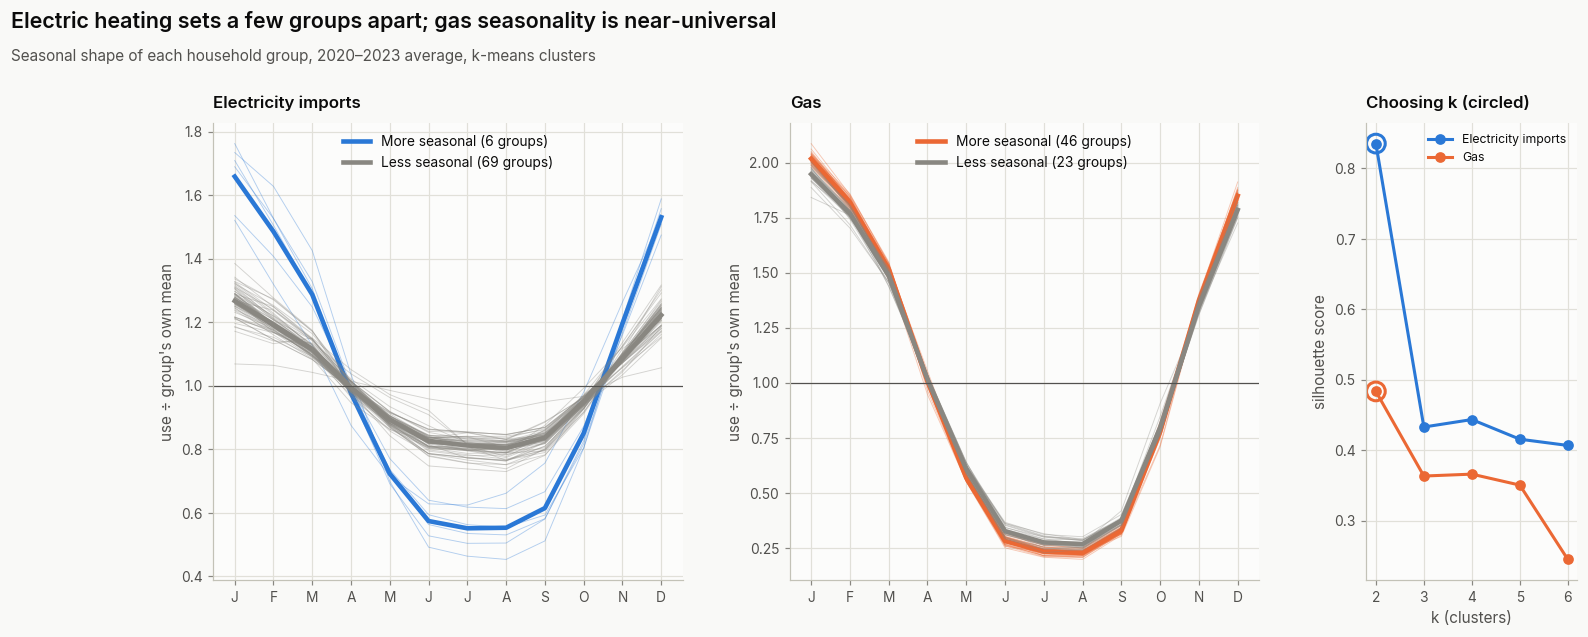

                                   kwh_per_day_2023  winter_to_summer  change_2020_2023_pct
quantity            cluster                                                                
Electricity imports Less seasonal              8.84              1.51                -18.28
                    More seasonal             13.09              2.83                -20.16
Gas                 Less seasonal             27.54              6.38                -18.70
                    More seasonal             30.31              7.70                -20.14


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def choose_k(X, ks=range(2, 7)):
    scores = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=42).fit_predict(X)) for k in ks}
    best = max(scores.values())
    return max(k for k, s in scores.items() if s >= best - 0.01), scores


assignments, sil = [], []
fig = plt.figure(figsize=(16, 5.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.45], wspace=0.28)
for col, (q, color) in enumerate(QUANTITIES.items()):
    ax = fig.add_subplot(gs[col])
    shapes = pd.DataFrame({g: s.groupby(s.index.month).mean() / s.mean() for g, s in series[q].items()}).T
    k, scores = choose_k(shapes)
    sil += [{"quantity": q, "k": kk, "silhouette": v, "chosen": kk == k} for kk, v in scores.items()]
    labels = KMeans(k, n_init=20, random_state=42).fit_predict(shapes)
    centroids = shapes.groupby(labels).mean()
    ratio = centroids[WINTER].mean(axis=1) / centroids[SUMMER].mean(axis=1)
    names = ["More seasonal", "Less seasonal"] if k == 2 else \
            ["Strongly seasonal", "Moderately seasonal", "Weakly seasonal"] if k == 3 else \
            [f"Seasonality rank {i + 1}" for i in range(k)]
    ranked = list(ratio.sort_values(ascending=False).index)
    name_of = {c: names[r] for r, c in enumerate(ranked)}
    shade = {c: color if r == 0 else INK["muted"] for r, c in enumerate(ranked)}
    print(f"{q}: silhouette by k {({kk: round(v, 3) for kk, v in scores.items()})} -> k = {k}")
    print(f"  largest monthly difference between cluster shapes: {(centroids.max() - centroids.min()).max():.2f} x the group mean")
    for c in ranked:
        members = shapes.index[labels == c].tolist()
        print(f"  {name_of[c]} (winter/summer ratio {ratio[c]:.2f}, {len(members)} groups):")
        print("    " + "; ".join(members))
        for g in members:
            ax.plot(range(12), shapes.loc[g], color=shade[c], lw=0.6, alpha=0.35)
        ax.plot(range(12), centroids.loc[c], color=shade[c], lw=3, label=f"{name_of[c]} ({len(members)} groups)")
    assignments += [{"quantity": q, "group_label": g, "cluster": name_of[lab]} for g, lab in zip(shapes.index, labels)]
    ax.set_xticks(range(12), [m[0] for m in MONTHS]); ax.axhline(1, color=INK["secondary"], lw=0.8)
    ax.set_ylabel("use ÷ group's own mean"); ax.set_title(q, loc="left", fontsize=11); ax.legend(loc="upper center")
ax = fig.add_subplot(gs[2])
sil = pd.DataFrame(sil)
for q, color in QUANTITIES.items():
    d = sil[sil["quantity"].eq(q)]
    ax.plot(d["k"], d["silhouette"], color=color, marker="o", label=q)
    ax.scatter(d.loc[d["chosen"], "k"], d.loc[d["chosen"], "silhouette"], s=150, facecolor="none", edgecolor=color, lw=2)
ax.set_xlabel("k (clusters)"); ax.set_ylabel("silhouette score"); ax.set_xticks(range(2, 7))
ax.set_title("Choosing k (circled)", loc="left", fontsize=11); ax.legend(fontsize=8)
fig.text(0.01, 1.04, "Electric heating sets a few groups apart; gas seasonality is near-universal",
         fontsize=14, fontweight=plots.TITLE_WEIGHT, color=INK["primary"])
fig.text(0.01, 0.985, "Seasonal shape of each household group, 2020–2023 average, k-means clusters", fontsize=10,
         color=INK["secondary"])
reporter.save_fig(fig, "seasonal-shape-clusters")
plt.show()

clusters = pd.DataFrame(assignments).merge(seasonality, on=["quantity", "group_label"])
print(clusters.groupby(["quantity", "cluster"])[["kwh_per_day_2023", "winter_to_summer", "change_2020_2023_pct"]]
      .mean().round(2).to_string())
reporter.save_table(clusters, "group_clusters")
reporter.save_table(sil, "cluster_silhouette_scores")

## Conclusions

- **Electricity:** homes with electric heating (and PV homes) form a separate, much more seasonal cluster: winter use about 2.8 times summer use, against about 1.5 times for every other group. For PV homes this mainly reflects lower *summer imports*, because solar covers part of the demand.
- **Gas:** every group follows almost the same seasonal shape, so gas seasonality is close to universal. The two clusters differ only slightly: less efficient, older and single-occupant homes have a stronger winter peak; renters, flats and newer homes a weaker one.
- **Every group cut back:** all groups used less electricity and gas in 2023 than in 2020.
- **Deprivation does not define a seasonal type:** groups linked to energy poverty are spread across the same clusters as their comparators.

## Limitations

- Groups overlap (a household is in its region, its EPC band, its tenure, …), so the 75 points are not independent and clusters describe group *averages*.
- PV homes' monthly figures after 2021 rest on fewer homes; PV is kept here only as a group label, not interpreted beyond the shape.
- Six gas series (mostly non-gas heating systems) are incomplete and skipped.
